In [1]:
!pip install pytorch_fid
!pip install torchmetrics[image] torch-fidelity

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 21.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [torch-fidelity]


In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
import math
import torch
from pytorch_fid.fid_score import calculate_fid_given_paths
from torchmetrics.image.inception import InceptionScore
import os
from PIL import Image

In [3]:
!unzip -q cifar10.zip

In [4]:
transform = transforms.Compose([
    transforms.ToTensor()
])

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=transform
)
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [5]:
T = 1000
s = 8e-3

# Standard cosine beta schedule (corrected step division)
steps = torch.linspace(
    0, T, T + 1,
    dtype=torch.float64,
    device=device
)
alpha_bar = torch.cos(((steps / T + s) / (1 + s)) * math.pi / 2) ** 2
alpha_bar = alpha_bar / alpha_bar[0]

betas = 1 - alpha_bar[1:] / alpha_bar[:-1]
betas = betas.clamp(min=1e-5, max=0.999).float()

alphas = 1.0 - betas
alpha_time_t = torch.cumprod(alphas, dim=0)

In [6]:
def q_sample(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)

    sqrt_alpha_time_t = torch.sqrt(alpha_time_t[t])
    sqrt_one_minus_alpha_time_t = torch.sqrt(1 - alpha_time_t[t])

    # Reshape so the values can be multiplied across the entire picture
    sqrt_alpha_time_t = sqrt_alpha_time_t[:, None, None, None]
    sqrt_one_minus_alpha_time_t = sqrt_one_minus_alpha_time_t[:, None, None, None]

    xt = (
        sqrt_alpha_time_t * x0
        + sqrt_one_minus_alpha_time_t * noise
    )

    return xt, noise

In [7]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        device = t.device

        half_dim = self.dim // 2

        emb_scale = math.log(10000) / (half_dim - 1)

        emb = torch.exp(
            torch.arange(half_dim, device=device) * -emb_scale
        )

        emb = t.float()[:, None] * emb[None, :]

        emb = torch.cat(
            [torch.sin(emb), torch.cos(emb)],
            dim=1
        )

        return emb

In [8]:
class block(nn.Module):
    def __init__(self, in_channels, out_channels, num_groups=8):
        super().__init__()
        self.normalize = nn.GroupNorm(num_groups, in_channels)
        self.convolute = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
        self.act_func = nn.SiLU()

    def forward(self, x):
        x = self.normalize(x)
        x = self.act_func(x)
        x = self.convolute(x)
        return x


In [9]:
class resnetblock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()
        self.mlp = nn.Linear(time_dim, out_channels)
        self.block1 = block(in_channels, out_channels)
        self.block2 = block(out_channels, out_channels)

        if in_channels != out_channels:
            self.residual = nn.Conv2d(in_channels, out_channels, kernel_size = 1)
        else: self.residual = nn.Identity()

    def forward(self, x, time_emb):
        h = self.block1(x)
        time_emb = self.mlp(time_emb)
        time_emb = time_emb[:, :, None, None]
        h = h + time_emb
        h = self.block2(h)

        return h + self.residual(x)



In [10]:
class UNet(nn.Module):
    def __init__(self, in_channels=3, base_channels=64, time_dim=128):
        super().__init__()
        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )
        #initial convolution to get 64 channels from the base 1 channel since the pictures are greyscale
        self.input_conv = nn.Conv2d(in_channels, base_channels, kernel_size=3, padding=1)

        #first downblock, convoluting and learning features while sending skip connection to upblocks
        self.downblock1 = resnetblock(base_channels, base_channels, time_dim)

        #first downsample, where number of channels increases for more feature learning and stride=2 to turn the 28 by 28 pictures into 14 by 14
        self.downsample1 = nn.Conv2d(base_channels, base_channels * 2, kernel_size = 4, stride=2, padding=1)

        self.downblock2 = resnetblock(base_channels * 2, base_channels * 2, time_dim)

        self.downsample2 = nn.Conv2d(base_channels * 2, base_channels * 4, kernel_size=4, stride=2, padding=1)

        self.bottleneck1 = resnetblock(base_channels * 4, base_channels * 4, time_dim)

        self.bottleneck2 = resnetblock(base_channels * 4, base_channels * 4, time_dim)

        #first upsample, reducing number of channels and increasing from 7 by 7 image to 14 by 14 using convtranspose2d
        self.upsample1 = nn.ConvTranspose2d(base_channels * 4, base_channels * 2, kernel_size = 4, stride=2, padding=1)

        # Fix: input channels for upblock1 should be base_channels * 4 due to concatenation
        self.upblock1 = resnetblock(base_channels * 4, base_channels * 2, time_dim)

        self.upsample2 = nn.ConvTranspose2d(base_channels * 2, base_channels, kernel_size=4, stride=2, padding=1)

        # Fix: input channels for upblock2 should be base_channels * 2 due to concatenation
        self.upblock2 = resnetblock(base_channels * 2, base_channels, time_dim)

        self.output = nn.Conv2d(base_channels, in_channels, kernel_size=1)

    def forward(self, x, t):
        t_emb = self.time_embedding(t)
        x = self.input_conv(x)
        d1 = self.downblock1(x, t_emb)
        x = self.downsample1(d1)
        d2 = self.downblock2(x, t_emb)
        x = self.downsample2(d2)
        x = self.bottleneck1(x, t_emb)
        x = self.bottleneck2(x, t_emb)
        x = self.upsample1(x)
        x = torch.cat([x, d2], dim=1)
        u1 = self.upblock1(x, t_emb)
        x = self.upsample2(u1)
        x = torch.cat([x, d1], dim=1)
        u2 = self.upblock2(x, t_emb)
        return self.output(u2)


In [11]:
model = UNet().to(device)
#model.load_state_dict(torch.load(PATH))
num_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"{num_params:,} parameters")

4,789,699 parameters


In [ ]:

PATH = "/content/gdrive/My Drive/ddpm_cifar_300.pt"
model.load_state_dict(torch.load(PATH, map_location=torch.device(device)))

Mounted at /content/gdrive


<All keys matched successfully>

In [15]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-4,
    weight_decay=1e-4
)
from google.colab import drive
drive.mount('/content/gdrive')
checkpoint = torch.load("/content/gdrive/My Drive/ddim_cifar_300_real.pth", weights_only=True)
model.load_state_dict(checkpoint['model_state_dict'])
optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
start_epoch = checkpoint['epoch']
loss = checkpoint['loss']

num_epochs = 300

loss_history = []



Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [ ]:
for epoch in range(start_epoch, num_epochs):

    print("epoch number: ", epoch)

    model.train()

    for x0, _ in train_loader:
        x0 = x0.to(device)

        batch_size = x0.shape[0]

        # Random timestep for each image
        t = torch.randint(
            0,
            T,
            (batch_size,), device=device
        )

        # Random Gaussian noise
        noise = torch.randn_like(x0)

        # Forward diffusion
        xt, _ = q_sample(
            x0,
            t,
            noise
        )


        # Predict the noise
        pred_noise = model(
            xt,
            t
        )

        # DDPM loss
        loss = F.mse_loss(
            pred_noise,
            noise
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        loss_history.append(loss.item())

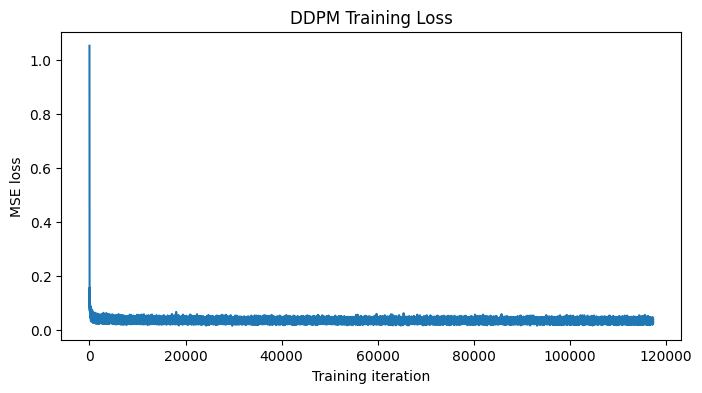

0.016697002574801445


In [13]:
plt.figure(figsize=(8, 4))

plt.plot(loss_history)

plt.xlabel("Training iteration")
plt.ylabel("MSE loss")
plt.title("DDPM Training Loss")

plt.show()
print(min(loss_history))

In [14]:
from google.colab import drive
drive.mount('/content/gdrive')
checkpoint = {
    'epoch': epoch,
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'loss': loss,
}


PATH = "/content/gdrive/My Drive/ddim_cifar_300_real.pth"
torch.save(checkpoint, PATH)

Mounted at /content/gdrive


In [16]:
@torch.no_grad()
def sample_ddim(
    model,
    n_samples,
    image_size=32,
    steps=1000,
    eta=1.0
):
    model.eval()

    x = torch.randn(
        n_samples,
        3,
        image_size,
        image_size,
        device=device
    )

    bigT = torch.linspace(
        0, T-1, steps=steps, device=device
    ).round().long().flip(0)

    for i, t_value in enumerate(bigT):
        t_value = int(t_value.item())

        if i + 1 < len(bigT):
            prev_t = int(bigT[i + 1].item())
            alpha_bar_prev = alpha_time_t[prev_t]
        else:
            alpha_bar_prev = torch.ones(
                (), device=device, dtype=alpha_time_t.dtype
            )

        alpha_bar_t = alpha_time_t[t_value]

        t = torch.full(
            (n_samples,),
            t_value,
            device=device,
            dtype=torch.long
        )

        # Predict noise
        pred_noise = model(x, t)

        # Predict original image
        x0_pred = (
            x - torch.sqrt(1 - alpha_bar_t) * pred_noise
        ) / torch.sqrt(alpha_bar_t)

        # Calculate DDIM variance (sigma)
        sigma = eta * torch.sqrt(
            ((1 - alpha_bar_prev) / (1 - alpha_bar_t))
            * (1 - alpha_bar_t / alpha_bar_prev)
        )

        # Calculate direction pointing toward noise
        direction = torch.sqrt(
            (1 - alpha_bar_prev - sigma**2).clamp(min=0)
        ) * pred_noise

        # Add stochastic noise
        noise = torch.randn_like(x) if eta > 0 else torch.zeros_like(x)

        # Update sample
        x = (
            torch.sqrt(alpha_bar_prev) * x0_pred
            + direction
            + sigma * noise
        )

    return x


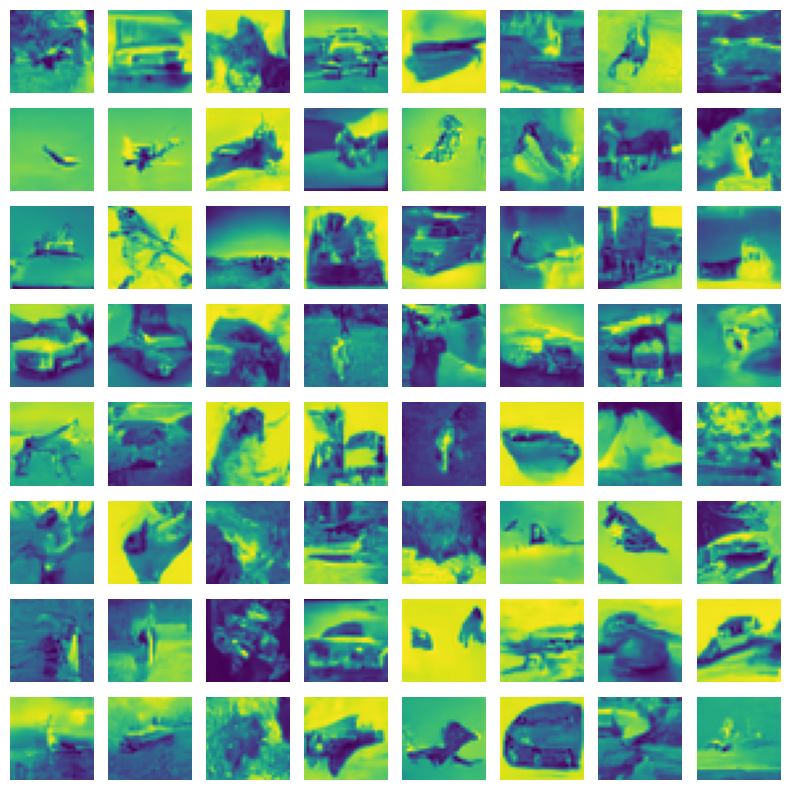

In [17]:
samples = sample_ddim(model, n_samples = 64) #100 steps
fig, axes = plt.subplots(
    8, 8,
    figsize=(8, 8)
)

for ax, image in zip(
    axes.flatten(),
    samples
):
    ax.imshow(
        image[0].cpu()
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [18]:

def batch_sample_gen(n_samples, batches, model, generated_dir):

    inception_score = InceptionScore(
        splits=12,
        normalize=True
    )

    os.makedirs(generated_dir, exist_ok=True)

    samples_per_batch = n_samples // batches

    for i in range(batches):

        print("Batch number:", i)

        samples = sample_ddim(
            model,
            n_samples=samples_per_batch
        )

        # Convert [-1, 1] to [0, 1]
        samples = (samples.clamp(-1, 1) + 1) / 2

        # Update IS using normalized images
        is_samples = samples[0:100]
        inception_score.update(is_samples.to('cpu'))

        # Convert to uint8 for saving
        images = (samples * 255).round().to(torch.uint8)

        for j, img in enumerate(images):

            # [C, H, W] -> [H, W, C]
            img = img.permute(1, 2, 0).cpu().numpy()

            pic_no = i * samples_per_batch + j

            Image.fromarray(img).save(
                os.path.join(
                    generated_dir,
                    f"{pic_no:05d}.png"
                )
            )

    # Calculate IS once across all generated images
    is_mean, is_std = inception_score.compute()

    return is_mean.item(), is_std.item()


In [19]:
generated_dir = "./generated_cifar"
os.makedirs(generated_dir, exist_ok=True)

In [20]:
is_mean, is_std = batch_sample_gen(n_samples=3000, batches=30, model=model, generated_dir=generated_dir)

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `InceptionScore` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)
Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:01<00:00, 84.8MB/s]


Batch number: 0
Batch number: 1
Batch number: 2
Batch number: 3
Batch number: 4
Batch number: 5
Batch number: 6
Batch number: 7
Batch number: 8
Batch number: 9
Batch number: 10
Batch number: 11
Batch number: 12
Batch number: 13
Batch number: 14
Batch number: 15
Batch number: 16
Batch number: 17
Batch number: 18
Batch number: 19
Batch number: 20
Batch number: 21
Batch number: 22
Batch number: 23
Batch number: 24
Batch number: 25
Batch number: 26
Batch number: 27
Batch number: 28
Batch number: 29


In [21]:
real_dir = "./real_cifar"
os.makedirs(real_dir, exist_ok=True)

counter = 0
n_samples = 3000

for images, _ in train_loader:
    for image in images:
        if counter >= n_samples:
            break

        # Convert [-1, 1] -> [0, 1] -> [0, 255]
        image = (image.clamp(-1, 1) + 1) / 2
        image = (image * 255).round().to(torch.uint8)

        # [C, H, W] -> [H, W, C]
        image = image.permute(1, 2, 0).cpu().numpy()

        Image.fromarray(image).save(
            os.path.join(real_dir, f"{counter:05d}.png")
        )

        counter += 1

    if counter >= n_samples:
        break

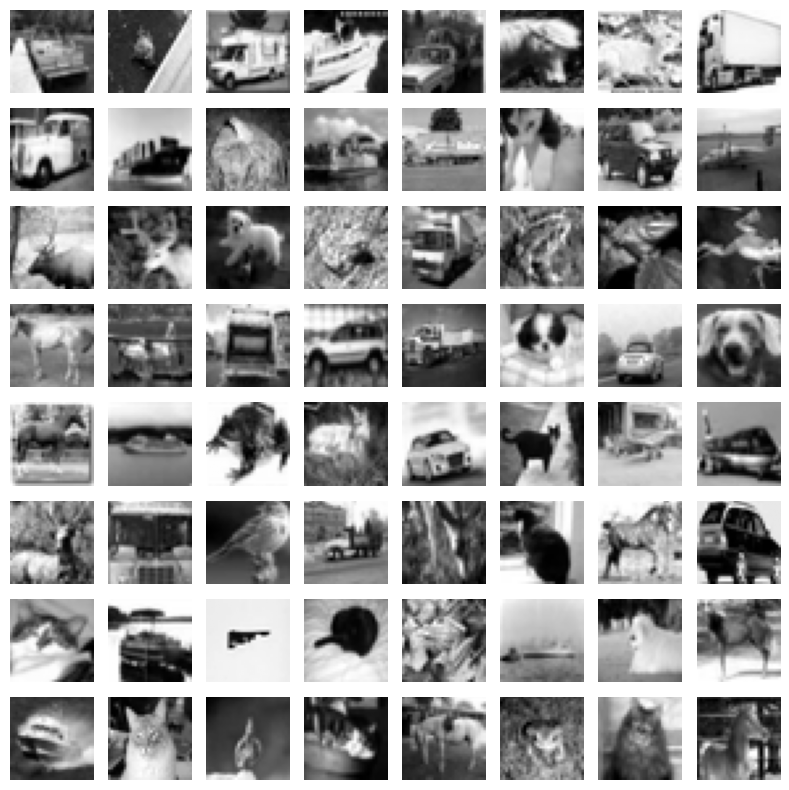

In [ ]:
images, labels = next(iter(train_loader))
fig, axes = plt.subplots(
    8, 8,
    figsize=(8, 8)
)

for ax, image in zip(
    axes.flatten(),
    images
):
    ax.imshow(
        image[0].cpu(),
        cmap="gray"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [28]:
fid_value = calculate_fid_given_paths(
    paths=['./real_cifar', './generated_cifar'],
    batch_size=100,
    device='cuda',
    dims=2048
)
print(f"FID score: {fid_value}")
print(f"IS score and stddev: {is_mean}, {is_std}")

100%|██████████| 30/30 [00:13<00:00,  2.19it/s]


FID score: 43.134274272991775
IS score and stddev: 5.634130001068115, 0.35424700379371643
